Mounted at /content/drive
Number of Images: 379
Number of Masks: 0


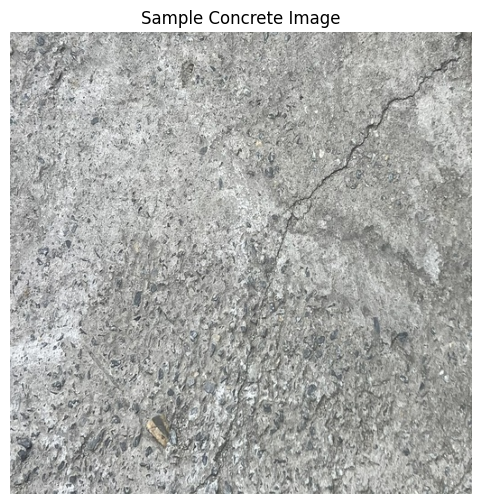

In [4]:
# Import required libraries
import os
import glob
import cv2
import matplotlib.pyplot as plt

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define dataset paths
image_dir = "/content/drive/MyDrive/Image_Processing_Project/Concrete400/Segmentation/Image"
mask_dir = "/content/drive/MyDrive/Image_Processing_Project/Concrete400/Segmentation/Masks"

# Get image and mask file paths
image_paths = sorted(glob.glob(os.path.join(image_dir, "*.jpg")))
mask_paths = sorted(glob.glob(os.path.join(mask_dir, "*.png")))

# Check dataset loading
print("Number of Images:", len(image_paths))
print("Number of Masks:", len(mask_paths))

# Load one sample image
sample_image = cv2.imread(image_paths[0])
sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)

# Display sample image
plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.title("Sample Concrete Image")
plt.axis("off")
plt.show()

In [ ]:
# Check dimensions and shapes of dataset images

print("Total Images:", len(image_paths))

# Load dimensions of all images
image_shapes = []

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        image_shapes.append(img.shape)

# Display unique image shapes
unique_shapes = set(image_shapes)

print("Unique Image Shapes:", unique_shapes)
print("Number of Valid Images:", len(image_shapes))

Total Images: 379
Unique Image Shapes: {(512, 512, 3)}
Number of Valid Images: 379


In [ ]:
# Check data types of dataset images

image_dtypes = set()

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        image_dtypes.add(img.dtype)

print("Unique Image Data Types:", image_dtypes)

Unique Image Data Types: {dtype('uint8')}


In [ ]:
# Check intensity range of dataset images

global_min = 255
global_max = 0

for path in image_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        global_min = min(global_min, img.min())
        global_max = max(global_max, img.max())

print("Minimum Intensity:", global_min)
print("Maximum Intensity:", global_max)

Minimum Intensity: 0
Maximum Intensity: 255


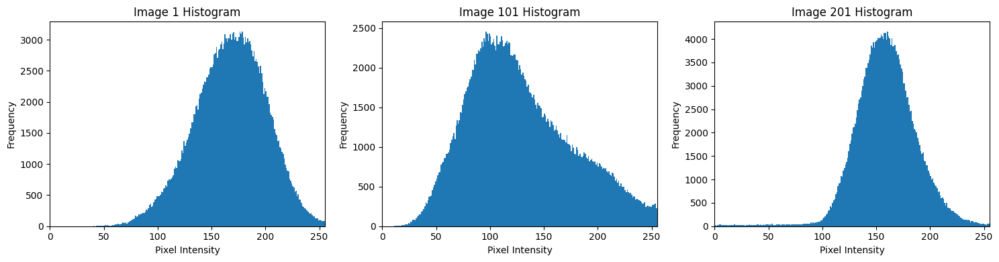

In [ ]:
# Generate histograms for 3 sample images

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 4))

for i, index in enumerate(sample_indices):
    img = cv2.imread(image_paths[index], cv2.IMREAD_GRAYSCALE)

    plt.subplot(1, 3, i + 1)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Image {index + 1} Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.xlim(0, 255)

plt.tight_layout()
plt.show()

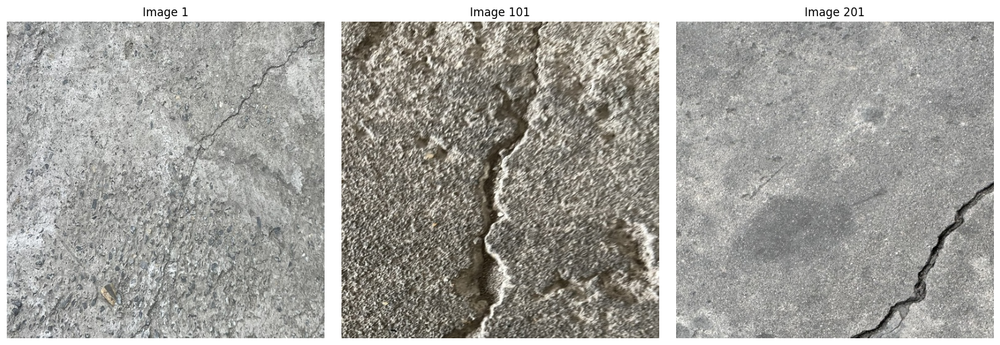

In [ ]:
# Visual inspection for noise analysis

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 5))

for i, index in enumerate(sample_indices):
    img = cv2.imread(image_paths[index])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"Image {index + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

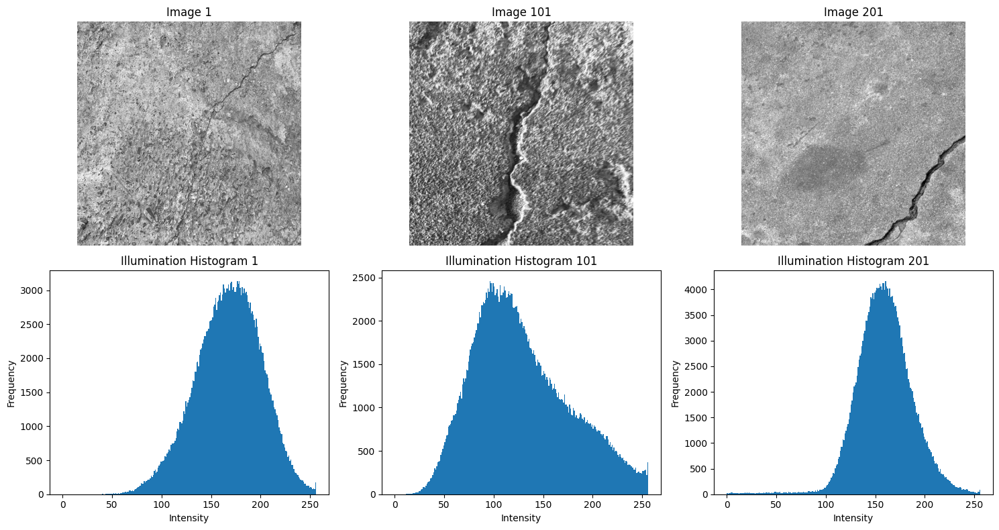

In [ ]:
# Analyze illumination in sample images

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 8))

for i, index in enumerate(sample_indices):

    img = cv2.imread(image_paths[index], cv2.IMREAD_GRAYSCALE)

    # Display grayscale image
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"Image {index + 1}")
    plt.axis("off")

    # Display intensity histogram
    plt.subplot(2, 3, i + 4)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Illumination Histogram {index + 1}")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

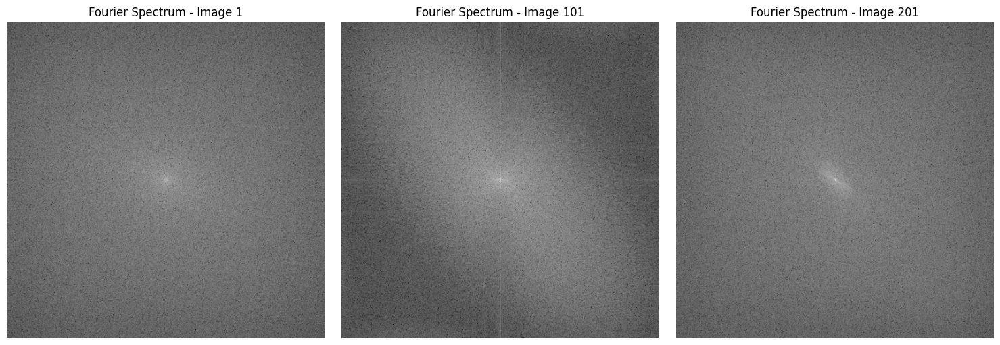

In [ ]:
import numpy as np
# Generate Centered Log-Magnitude Fourier Spectrum

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 5))

for i, index in enumerate(sample_indices):

    # Load grayscale image
    img = cv2.imread(image_paths[index], cv2.IMREAD_GRAYSCALE)

    # Apply 2D Fourier Transform
    fft = np.fft.fft2(img)

    # Shift zero frequency to the center
    fft_shift = np.fft.fftshift(fft)

    # Calculate log magnitude spectrum
    magnitude_spectrum = 20 * np.log(
        np.abs(fft_shift) + 1
    )

    # Display spectrum
    plt.subplot(1, 3, i + 1)
    plt.imshow(magnitude_spectrum, cmap="gray")
    plt.title(f"Fourier Spectrum - Image {index + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

# Create Image Analysis results directory
results_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Image_Analysis"

os.makedirs(results_dir, exist_ok=True)

print("Results folder created successfully!")
print("Path:", results_dir)

Results folder created successfully!
Path: /content/drive/MyDrive/Image_Processing_Project/Results/Image_Analysis


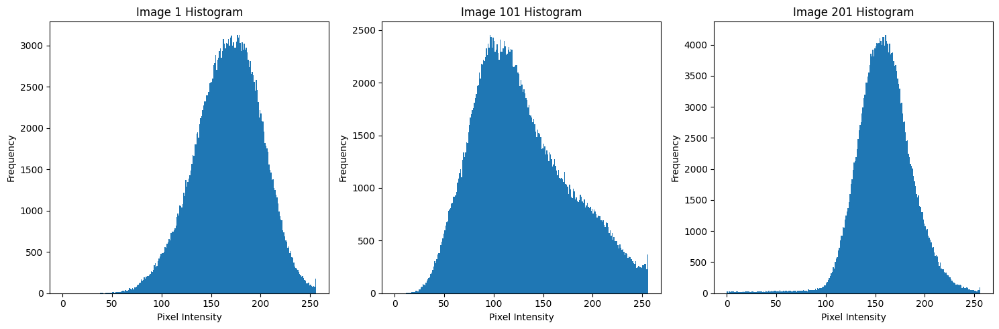

In [ ]:
# Save histogram visualizations

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 5))

for i, index in enumerate(sample_indices):
    img = cv2.imread(image_paths[index], cv2.IMREAD_GRAYSCALE)

    plt.subplot(1, 3, i + 1)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Image {index + 1} Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "image_histograms.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

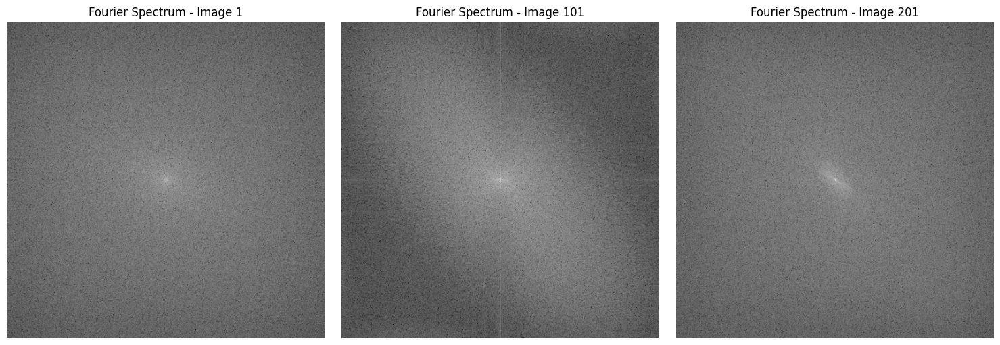

In [ ]:
# Save Fourier spectrum visualizations

sample_indices = [0, 100, 200]

plt.figure(figsize=(15, 5))

for i, index in enumerate(sample_indices):
    img = cv2.imread(image_paths[index], cv2.IMREAD_GRAYSCALE)

    fft = np.fft.fft2(img)
    fft_shift = np.fft.fftshift(fft)

    magnitude_spectrum = 20 * np.log(
        np.abs(fft_shift) + 1
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(magnitude_spectrum, cmap="gray")
    plt.title(f"Fourier Spectrum - Image {index + 1}")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "fourier_spectrum.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Verify saved analysis results

print("Saved Files:")

for file in os.listdir(results_dir):
    print("-", file)

Saved Files:
- image_histograms.png
- fourier_spectrum.png


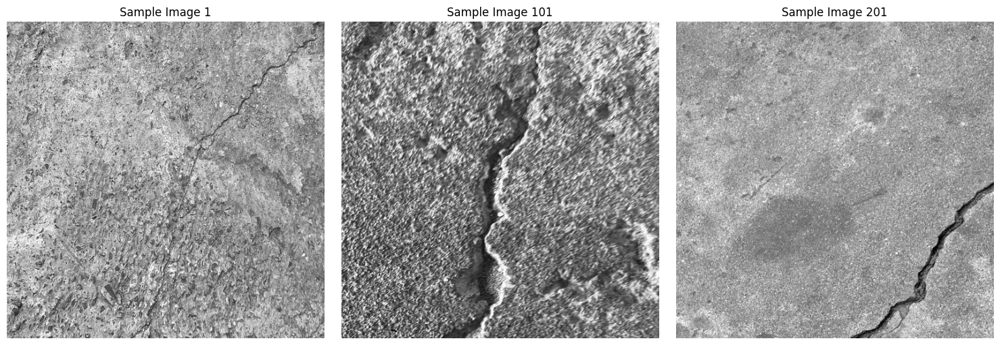

Number of Selected Images: 3
Image Shape: (512, 512)


In [ ]:
# Resolution & Gray-Level Study
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select sample images
sample_indices = [0, 100, 200]

# Load images in grayscale
sample_images = []

for index in sample_indices:
    img = cv2.imread(
        image_paths[index],
        cv2.IMREAD_GRAYSCALE
    )

    sample_images.append(img)

# Display selected images
plt.figure(figsize=(15, 5))

for i, img in enumerate(sample_images):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"Sample Image {sample_indices[i] + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of Selected Images:", len(sample_images))
print("Image Shape:", sample_images[0].shape)

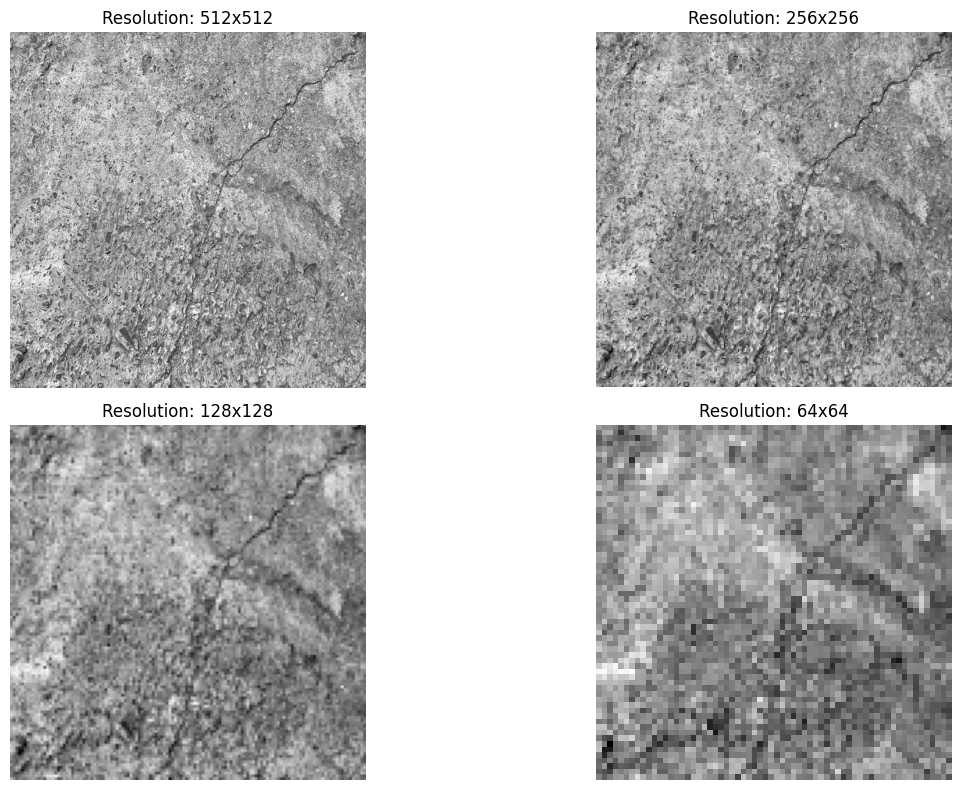

In [ ]:
# Resolution Reduction Experiment

resolutions = [
    (512, 512),
    (256, 256),
    (128, 128),
    (64, 64)
]

# Select one sample image
original_img = sample_images[0]

plt.figure(figsize=(14, 8))

for i, size in enumerate(resolutions):

    # Resize image
    resized_img = cv2.resize(
        original_img,
        size,
        interpolation=cv2.INTER_AREA
    )

    # Display resized image
    plt.subplot(2, 2, i + 1)
    plt.imshow(resized_img, cmap="gray")
    plt.title(f"Resolution: {size[0]}x{size[1]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

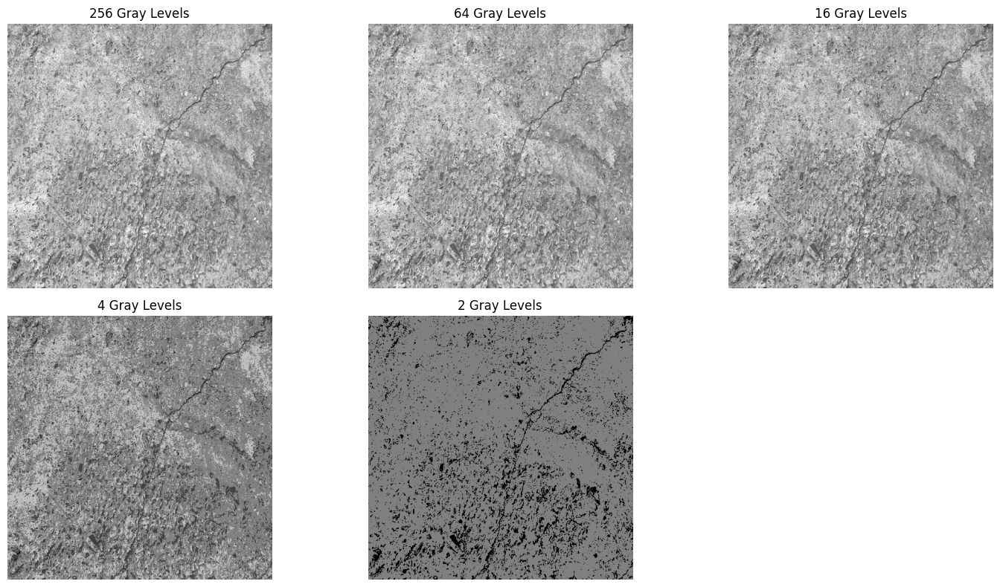

In [ ]:
# Gray-Level Quantization Experiment

gray_levels = [256, 64, 16, 4, 2]

original_img = sample_images[0]

plt.figure(figsize=(15, 8))

for i, levels in enumerate(gray_levels):

    # Calculate quantization factor
    factor = 256 // levels

    # Apply gray-level quantization
    quantized_img = (
        original_img // factor
    ) * factor

    # Display image
    plt.subplot(2, 3, i + 1)
    plt.imshow(quantized_img, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{levels} Gray Levels")
    plt.axis("off")

plt.tight_layout()
plt.show()

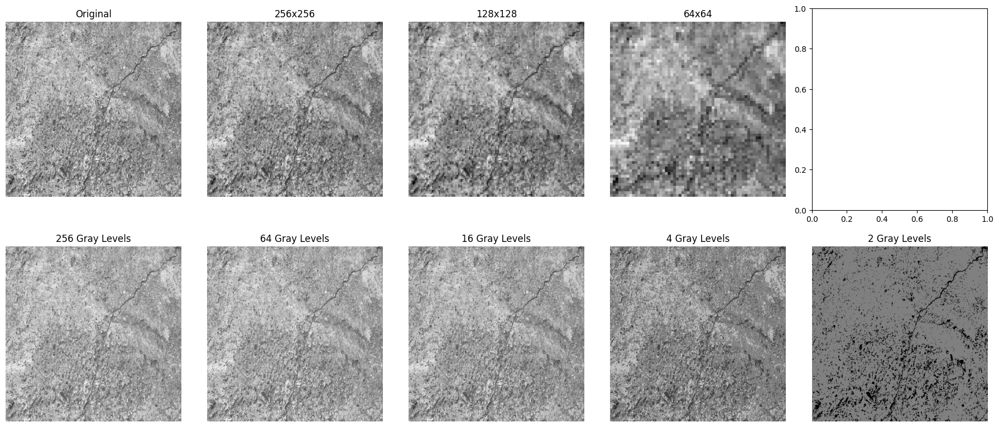

In [ ]:
# Combined Resolution and Gray-Level Comparison

original_img = sample_images[0]

resolutions = [512, 256, 128, 64]
gray_levels = [256, 64, 16, 4, 2]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# Original image
axes[0, 0].imshow(original_img, cmap="gray")
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# Resolution reduction
for i, resolution in enumerate(resolutions[1:], start=1):

    resized = cv2.resize(
        original_img,
        (resolution, resolution),
        interpolation=cv2.INTER_AREA
    )

    # Resize back for visual comparison
    restored = cv2.resize(
        resized,
        (512, 512),
        interpolation=cv2.INTER_NEAREST
    )

    axes[0, i].imshow(restored, cmap="gray")
    axes[0, i].set_title(f"{resolution}x{resolution}")
    axes[0, i].axis("off")

# Gray-level quantization
for i, levels in enumerate(gray_levels):

    factor = 256 // levels
    quantized = (original_img // factor) * factor

    axes[1, i].imshow(
        quantized,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[1, i].set_title(f"{levels} Gray Levels")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Resolution", fontsize=12)
axes[1, 0].set_ylabel("Gray Levels", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
#------------------------------------------------------------------------------------------
# Create output directory

study_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Resolution_GrayLevel"

os.makedirs(study_dir, exist_ok=True)

# Save comparison figure
fig.savefig(
    os.path.join(study_dir, "resolution_graylevel_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

print("Comparison saved successfully!")
print("Saved at:", study_dir)

Comparison saved successfully!
Saved at: /content/drive/MyDrive/Image_Processing_Project/Results/Resolution_GrayLevel


In [ ]:
#-----------------------------------------------------------------------------------------
print("Saved Files:")

for file in os.listdir(study_dir):
    print("-", file)

Saved Files:
- resolution_graylevel_comparison.png


In [ ]:
from sklearn.model_selection import train_test_split

# Split image paths into development and test sets
dev_images, test_images = train_test_split(
    image_paths,
    test_size=0.30,
    random_state=42
)

print("Development Images:", len(dev_images))
print("Test Images:", len(test_images))
print("Total Images:", len(dev_images) + len(test_images))

Development Images: 265
Test Images: 114
Total Images: 379


In [ ]:
# Inspect mask directory

print("Mask Directory:", mask_dir)

mask_files = os.listdir(mask_dir)

print("Total Files in Mask Folder:", len(mask_files))
print("First 10 Files:")

for file in mask_files[:10]:
    print(file)

Mask Directory: /content/drive/MyDrive/Image_Processing_Project/Concrete400/Segmentation/Masks
Total Files in Mask Folder: 379
First 10 Files:
image_001.jpg
image_002.jpg
image_003.jpg
image_004.jpg
image_005.jpg
image_006.jpg
image_007.jpg
image_008.jpg
image_009.jpg
image_010.jpg


In [ ]:
# Load mask paths using JPG extension

mask_paths = sorted(
    glob.glob(os.path.join(mask_dir, "*.jpg"))
)

# Create image-mask pairs
image_mask_pairs = []

for img_path, mask_path in zip(image_paths, mask_paths):

    img_name = os.path.basename(img_path)
    mask_name = os.path.basename(mask_path)

    if img_name == mask_name:
        image_mask_pairs.append((img_path, mask_path))

print("Total Image-Mask Pairs:", len(image_mask_pairs))
print("First Pair:")
print("Image:", os.path.basename(image_mask_pairs[0][0]))
print("Mask:", os.path.basename(image_mask_pairs[0][1]))

Total Image-Mask Pairs: 379
First Pair:
Image: image_001.jpg
Mask: image_001.jpg


In [ ]:
# Split image-mask pairs into development and test sets

dev_pairs, test_pairs = train_test_split(
    image_mask_pairs,
    test_size=0.30,
    random_state=42
)

print("Development Pairs:", len(dev_pairs))
print("Test Pairs:", len(test_pairs))
print("Total Pairs:", len(dev_pairs) + len(test_pairs))

Development Pairs: 265
Test Pairs: 114
Total Pairs: 379


In [ ]:
# Verify dataset split integrity

dev_image_names = {
    os.path.basename(img) for img, mask in dev_pairs
}

test_image_names = {
    os.path.basename(img) for img, mask in test_pairs
}

dev_mask_names = {
    os.path.basename(mask) for img, mask in dev_pairs
}

test_mask_names = {
    os.path.basename(mask) for img, mask in test_pairs
}

# Check for overlap
image_overlap = dev_image_names.intersection(test_image_names)
mask_overlap = dev_mask_names.intersection(test_mask_names)

# Check image-mask matching
valid_dev_pairs = all(
    os.path.basename(img) == os.path.basename(mask)
    for img, mask in dev_pairs
)

valid_test_pairs = all(
    os.path.basename(img) == os.path.basename(mask)
    for img, mask in test_pairs
)

print("Image Overlap:", len(image_overlap))
print("Mask Overlap:", len(mask_overlap))
print("Development Pairs Valid:", valid_dev_pairs)
print("Test Pairs Valid:", valid_test_pairs)

Image Overlap: 0
Mask Overlap: 0
Development Pairs Valid: True
Test Pairs Valid: True


In [ ]:
import pandas as pd

# Create development DataFrame
dev_df = pd.DataFrame(
    dev_pairs,
    columns=["image_path", "mask_path"]
)

# Create test DataFrame
test_df = pd.DataFrame(
    test_pairs,
    columns=["image_path", "mask_path"]
)

# Create split directory
split_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Dataset_Split"

os.makedirs(split_dir, exist_ok=True)

# Save CSV files
dev_df.to_csv(
    os.path.join(split_dir, "development_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(split_dir, "test_split.csv"),
    index=False
)

print("Dataset split saved successfully!")
print("Development:", len(dev_df))
print("Test:", len(test_df))
print("Saved Files:", os.listdir(split_dir))

Dataset split saved successfully!
Development: 265
Test: 114
Saved Files: ['development_split.csv', 'test_split.csv']


In [ ]:
# Load dataset splits

dev_df = pd.read_csv(
    "/content/drive/MyDrive/Image_Processing_Project/Results/Dataset_Split/development_split.csv"
)

test_df = pd.read_csv(
    "/content/drive/MyDrive/Image_Processing_Project/Results/Dataset_Split/test_split.csv"
)

# Load one sample mask from each set
dev_mask = cv2.imread(
    dev_df.iloc[0]["mask_path"],
    cv2.IMREAD_GRAYSCALE
)

test_mask = cv2.imread(
    test_df.iloc[0]["mask_path"],
    cv2.IMREAD_GRAYSCALE
)

print("Development Masks:", len(dev_df))
print("Test Masks:", len(test_df))

print("Development Mask Loaded:", dev_mask is not None)
print("Test Mask Loaded:", test_mask is not None)

Development Masks: 265
Test Masks: 114
Development Mask Loaded: True
Test Mask Loaded: True


In [ ]:
# Check mask dimensions and data types

dev_shapes = set()
test_shapes = set()

dev_dtypes = set()
test_dtypes = set()

for path in dev_df["mask_path"]:
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is not None:
        dev_shapes.add(mask.shape)
        dev_dtypes.add(mask.dtype)

for path in test_df["mask_path"]:
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is not None:
        test_shapes.add(mask.shape)
        test_dtypes.add(mask.dtype)

print("Development Mask Shapes:", dev_shapes)
print("Test Mask Shapes:", test_shapes)

print("Development Mask Data Types:", dev_dtypes)
print("Test Mask Data Types:", test_dtypes)

Development Mask Shapes: {(512, 512)}
Test Mask Shapes: {(512, 512)}
Development Mask Data Types: {dtype('uint8')}
Test Mask Data Types: {dtype('uint8')}


In [ ]:
# Analyze unique pixel values in sample masks

sample_mask_paths = dev_df["mask_path"].iloc[:5]

for i, path in enumerate(sample_mask_paths):

    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    unique_values, counts = np.unique(
        mask,
        return_counts=True
    )

    print(f"\nMask {i + 1}")
    print("Unique Pixel Values:", unique_values)
    print("Number of Unique Values:", len(unique_values))

    print("Most Frequent Values:")
    sorted_indices = np.argsort(counts)[::-1]

    for idx in sorted_indices[:5]:
        print(
            f"Value {unique_values[idx]}: {counts[idx]} pixels"
        )


Mask 1
Unique Pixel Values: [  0   1   2   3   4   5   6   7   8   9  13  31  57  60  84  87  90  91
 101 102 116 117 118 119 120 121 122 134 135 136 137 138 139 140 149 167
 170 182 195 197 220 223 243 249 250 251 252 253 254 255]
Number of Unique Values: 50
Most Frequent Values:
Value 0: 257146 pixels
Value 255: 1783 pixels
Value 1: 959 pixels
Value 2: 601 pixels
Value 254: 501 pixels

Mask 2
Unique Pixel Values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  85  86  87  88  89  90  91  92
  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108 109 110
 111 112 114 117 118 119 120 121 122 123 124 125 126 127 128 129 130 131
 132 133 134 135 136 137 138 139 140 141 142 144 145 147 148 149 150 

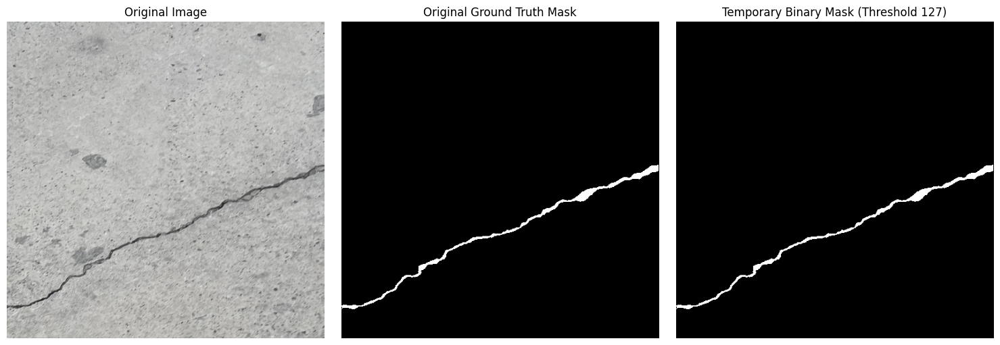

In [ ]:
# Visualize original image and ground truth mask

sample_path = dev_df.iloc[0]["image_path"]
mask_path = dev_df.iloc[0]["mask_path"]

original = cv2.imread(sample_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Temporary binary mask for visualization
_, binary_mask = cv2.threshold(
    mask, 127, 255, cv2.THRESH_BINARY
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary_mask, cmap="gray")
plt.title("Temporary Binary Mask (Threshold 127)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Apply binary threshold to all masks

def prepare_binary_mask(mask_path, threshold=127):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise ValueError(f"Could not load mask: {mask_path}")

    _, binary = cv2.threshold(
        mask,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    return binary


# Test on all development and test masks
dev_white_pixels = 0
dev_black_pixels = 0

test_white_pixels = 0
test_black_pixels = 0

for path in dev_df["mask_path"]:
    binary = prepare_binary_mask(path)

    dev_white_pixels += np.count_nonzero(binary == 255)
    dev_black_pixels += np.count_nonzero(binary == 0)

for path in test_df["mask_path"]:
    binary = prepare_binary_mask(path)

    test_white_pixels += np.count_nonzero(binary == 255)
    test_black_pixels += np.count_nonzero(binary == 0)


print("Development Ground Truth:")
print("White Pixels (Cracks):", dev_white_pixels)
print("Black Pixels (Background):", dev_black_pixels)

print("\nTest Ground Truth:")
print("White Pixels (Cracks):", test_white_pixels)
print("Black Pixels (Background):", test_black_pixels)

Development Ground Truth:
White Pixels (Cracks): 2139436
Black Pixels (Background): 67328724

Test Ground Truth:
White Pixels (Cracks): 918088
Black Pixels (Background): 28966328


In [ ]:
# Save prepared binary ground truth masks

ground_truth_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Ground_Truth"

dev_gt_dir = os.path.join(ground_truth_dir, "Development")
test_gt_dir = os.path.join(ground_truth_dir, "Test")

os.makedirs(dev_gt_dir, exist_ok=True)
os.makedirs(test_gt_dir, exist_ok=True)


# Save development masks
for path in dev_df["mask_path"]:

    binary_mask = prepare_binary_mask(path)

    filename = os.path.basename(path)

    cv2.imwrite(
        os.path.join(dev_gt_dir, filename),
        binary_mask
    )


# Save test masks
for path in test_df["mask_path"]:

    binary_mask = prepare_binary_mask(path)

    filename = os.path.basename(path)

    cv2.imwrite(
        os.path.join(test_gt_dir, filename),
        binary_mask
    )


print("Ground Truth Masks Saved Successfully!")

print("Development Masks:", len(os.listdir(dev_gt_dir)))
print("Test Masks:", len(os.listdir(test_gt_dir)))

Ground Truth Masks Saved Successfully!
Development Masks: 265
Test Masks: 114


In [ ]:
# Verify saved ground truth masks

sample_path = os.path.join(test_gt_dir, "image_001.jpg")

sample_gt = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

print("Sample Mask Loaded:", sample_gt is not None)

if sample_gt is not None:
    print("Unique Values:", np.unique(sample_gt))
    print("Shape:", sample_gt.shape)


Sample Mask Loaded: True
Unique Values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Shape: (512, 512)


In [ ]:
def save_binary_masks(df, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    for path in df["mask_path"]:
        binary_mask = prepare_binary_mask(path)

        filename = os.path.splitext(os.path.basename(path))[0] + ".png"
        output_path = os.path.join(output_dir, filename)

        cv2.imwrite(output_path, binary_mask)


dev_gt_png_dir = os.path.join(ground_truth_dir, "Development_PNG")
test_gt_png_dir = os.path.join(ground_truth_dir, "Test_PNG")

save_binary_masks(dev_df, dev_gt_png_dir)
save_binary_masks(test_df, test_gt_png_dir)

print("Development PNG Masks:", len(os.listdir(dev_gt_png_dir)))
print("Test PNG Masks:", len(os.listdir(test_gt_png_dir)))

Development PNG Masks: 265
Test PNG Masks: 114


In [ ]:
sample_gt = cv2.imread(
    os.path.join(test_gt_png_dir, "image_001.png"),
    cv2.IMREAD_GRAYSCALE
)

print("Sample Mask Loaded:", sample_gt is not None)

if sample_gt is not None:
    print("Unique Values:", np.unique(sample_gt))
    print("Shape:", sample_gt.shape)
    print("Data Type:", sample_gt.dtype)

Sample Mask Loaded: True
Unique Values: [  0 255]
Shape: (512, 512)
Data Type: uint8


In [ ]:
import numpy as np

# 1. Mean Squared Error
def calculate_mse(original, processed):
    original = original.astype(np.float64)
    processed = processed.astype(np.float64)

    return np.mean((original - processed) ** 2)


# 2. Peak Signal-to-Noise Ratio
def calculate_psnr(original, processed):
    mse = calculate_mse(original, processed)

    if mse == 0:
        return float("inf")

    max_pixel = 255.0

    return 10 * np.log10((max_pixel ** 2) / mse)


# 3. Intersection over Union
def calculate_iou(ground_truth, prediction):
    ground_truth = ground_truth > 127
    prediction = prediction > 127

    intersection = np.logical_and(
        ground_truth, prediction
    ).sum()

    union = np.logical_or(
        ground_truth, prediction
    ).sum()

    if union == 0:
        return 1.0

    return intersection / union


print("MSE, PSNR, and IoU functions created successfully!")

MSE, PSNR, and IoU functions created successfully!


In [ ]:
# Create a sample original image
original = np.array([
    [100, 150, 200],
    [120, 180, 220],
    [90,  140, 190]
], dtype=np.uint8)

# Create a slightly modified image
processed = np.array([
    [105, 145, 195],
    [125, 175, 215],
    [95,  135, 185]
], dtype=np.uint8)

# Calculate metrics
mse_value = calculate_mse(original, processed)
psnr_value = calculate_psnr(original, processed)

print("MSE:", mse_value)
print("PSNR:", psnr_value, "dB")

MSE: 25.0
PSNR: 34.15140352195873 dB


In [ ]:
# Ground Truth Mask
ground_truth = np.array([
    [255, 255,   0],
    [255, 255,   0],
    [  0,   0,   0]
], dtype=np.uint8)

# Predicted Mask
prediction = np.array([
    [255, 255,   0],
    [255,   0,   0],
    [  0,   0, 255]
], dtype=np.uint8)

iou_value = calculate_iou(ground_truth, prediction)

print("IoU:", iou_value)
print("IoU Percentage:", iou_value * 100, "%")

IoU: 0.6
IoU Percentage: 60.0 %


In [ ]:
# Case 1: Perfect Match
perfect_prediction = ground_truth.copy()

perfect_iou = calculate_iou(
    ground_truth,
    perfect_prediction
)

# Case 2: No Overlap
no_overlap_prediction = np.array([
    [0,   0,   255],
    [0,   0,   255],
    [255, 255, 0]
], dtype=np.uint8)

no_overlap_iou = calculate_iou(
    ground_truth,
    no_overlap_prediction
)

print("Perfect Match IoU:", perfect_iou)
print("No Overlap IoU:", no_overlap_iou)

Perfect Match IoU: 1.0
No Overlap IoU: 0.0


In [ ]:
metrics_code = '''
import numpy as np


def calculate_mse(original, processed):
    original = original.astype(np.float64)
    processed = processed.astype(np.float64)

    return np.mean((original - processed) ** 2)


def calculate_psnr(original, processed):
    mse = calculate_mse(original, processed)

    if mse == 0:
        return float("inf")

    max_pixel = 255.0

    return 10 * np.log10((max_pixel ** 2) / mse)


def calculate_iou(ground_truth, prediction):
    ground_truth = ground_truth > 127
    prediction = prediction > 127

    intersection = np.logical_and(
        ground_truth, prediction
    ).sum()

    union = np.logical_or(
        ground_truth, prediction
    ).sum()

    if union == 0:
        return 1.0

    return intersection / union
'''

metrics_dir = os.path.join(project_path, "Results", "Metrics")
os.makedirs(metrics_dir, exist_ok=True)

metrics_file = os.path.join(metrics_dir, "metrics.py")

with open(metrics_file, "w") as file:
    file.write(metrics_code)

print("Metrics module saved successfully!")
print("Location:", metrics_file)

Metrics module saved successfully!
Location: /content/drive/MyDrive/Image_Processing_Project/Results/Metrics/metrics.py


In [ ]:
import sys

sys.path.insert(0, metrics_dir)

from metrics import calculate_mse, calculate_psnr, calculate_iou

print("MSE:", calculate_mse(original, processed))
print("PSNR:", calculate_psnr(original, processed))
print("IoU:", calculate_iou(ground_truth, prediction))

print("\nMetrics Module Import: SUCCESS")

MSE: 25.0
PSNR: 34.15140352195873
IoU: 0.6

Metrics Module Import: SUCCESS


Image Loaded: True
Image Shape: (512, 512)
Data Type: uint8


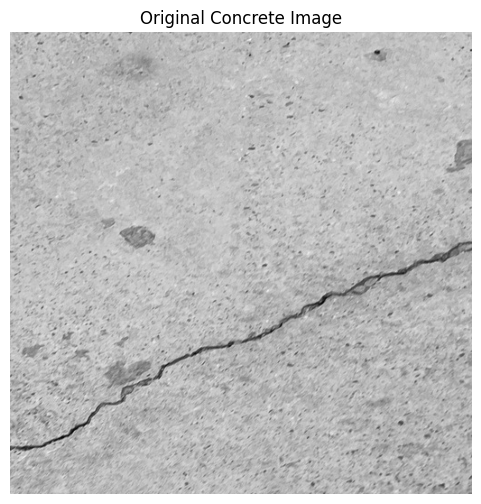

In [ ]:
# Select one sample image from Development set
sample_image_path = dev_df["image_path"].iloc[0]

# Load image in grayscale
original_image = cv2.imread(
    sample_image_path,
    cv2.IMREAD_GRAYSCALE
)

# Verify image
print("Image Loaded:", original_image is not None)
print("Image Shape:", original_image.shape)
print("Data Type:", original_image.dtype)

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(original_image, cmap="gray")
plt.title("Original Concrete Image")
plt.axis("off")
plt.show()

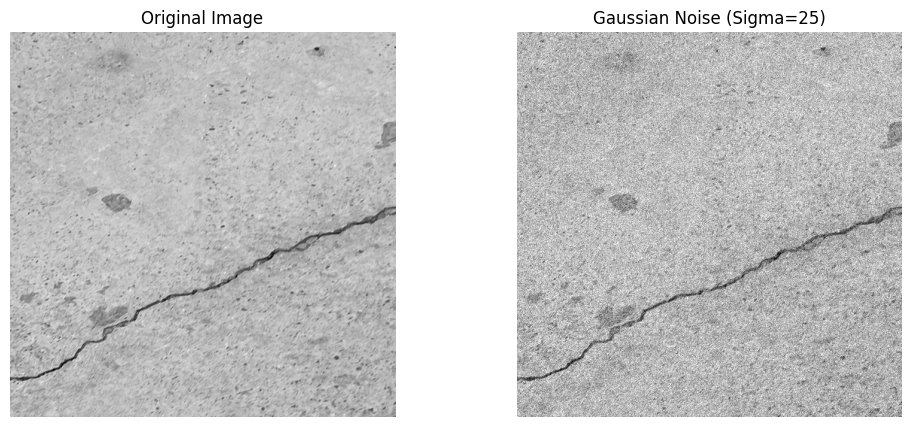

In [ ]:
# Generate Gaussian noise
mean = 0
sigma = 25

gaussian_noise = np.random.normal(
    mean,
    sigma,
    original_image.shape
)

# Add noise to original image
gaussian_noisy_image = original_image.astype(np.float32) + gaussian_noise

# Clip pixel values
gaussian_noisy_image = np.clip(
    gaussian_noisy_image, 0, 255
).astype(np.uint8)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_noisy_image, cmap="gray")
plt.title("Gaussian Noise (Sigma=25)")
plt.axis("off")

plt.show()

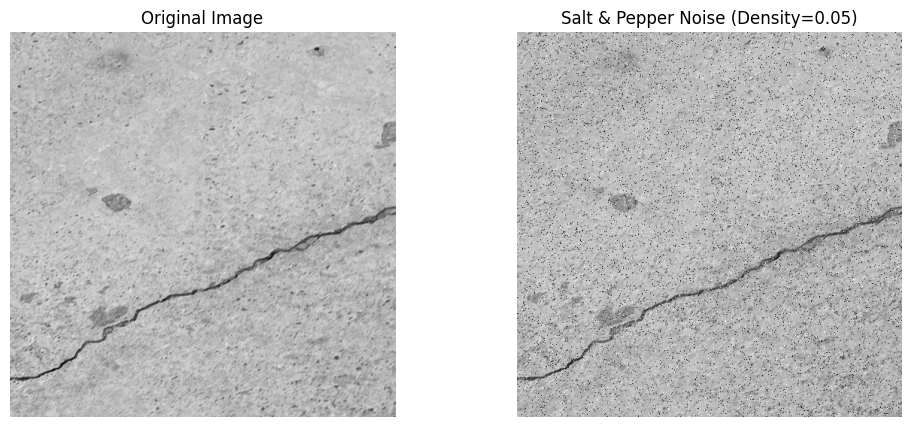

In [ ]:
# Set noise density
noise_density = 0.05

# Copy original image
salt_pepper_image = original_image.copy()

# Generate random values
random_matrix = np.random.random(original_image.shape)

# Add Pepper noise (black pixels)
salt_pepper_image[random_matrix < noise_density / 2] = 0

# Add Salt noise (white pixels)
salt_pepper_image[
    (random_matrix >= noise_density / 2) &
    (random_matrix < noise_density)
] = 255

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(salt_pepper_image, cmap="gray")
plt.title("Salt & Pepper Noise (Density=0.05)")
plt.axis("off")

plt.show()

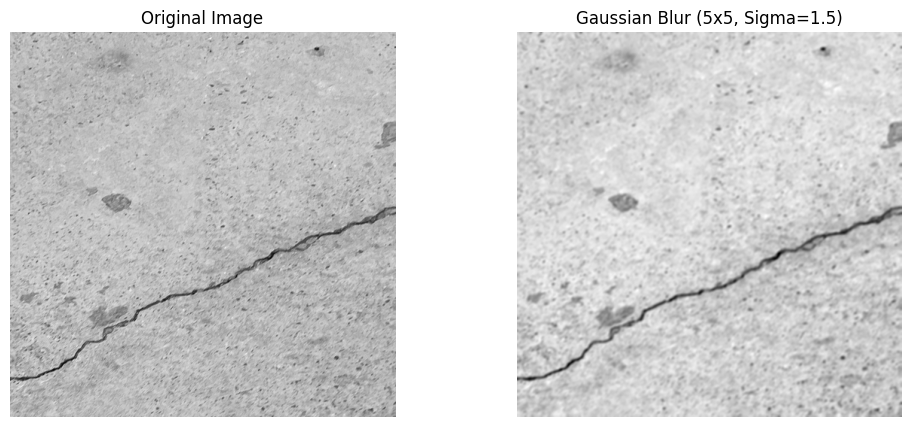

In [ ]:
# Apply Gaussian Blur
gaussian_blurred_image = cv2.GaussianBlur(
    original_image,
    (5, 5),
    sigmaX=1.5
)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_blurred_image, cmap="gray")
plt.title("Gaussian Blur (5x5, Sigma=1.5)")
plt.axis("off")

plt.show()

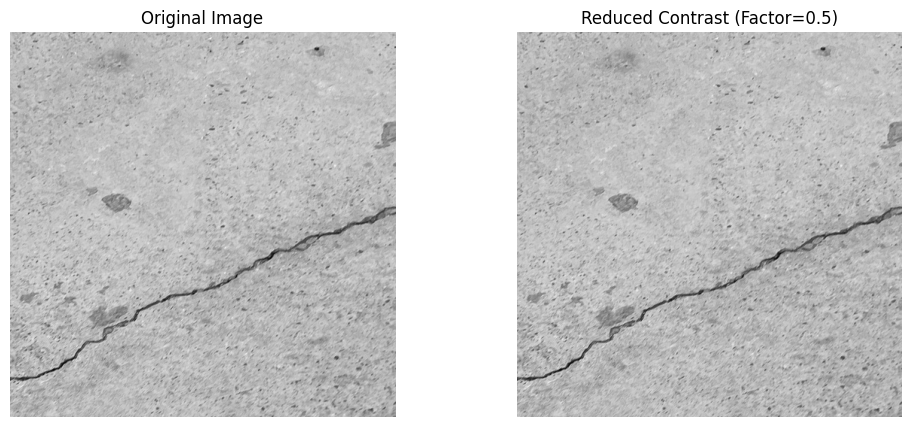

In [ ]:
# Reduce image contrast
contrast_factor = 0.5

reduced_contrast_image = (
    original_image.astype(np.float32) * contrast_factor
    + 127.5 * (1 - contrast_factor)
)

reduced_contrast_image = np.clip(
    reduced_contrast_image, 0, 255
).astype(np.uint8)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reduced_contrast_image, cmap="gray")
plt.title("Reduced Contrast (Factor=0.5)")
plt.axis("off")

plt.show()

In [ ]:
import pandas as pd

# Store degraded images
degraded_images = {
    "Gaussian Noise": gaussian_noisy_image,
    "Salt & Pepper Noise": salt_pepper_image,
    "Gaussian Blur": gaussian_blurred_image,
    "Reduced Contrast": reduced_contrast_image
}

# Calculate metrics
degradation_results = []

for name, degraded_image in degraded_images.items():

    mse = calculate_mse(original_image, degraded_image)
    psnr = calculate_psnr(original_image, degraded_image)

    degradation_results.append({
        "Degradation": name,
        "MSE": mse,
        "PSNR (dB)": psnr
    })

# Create results table
degradation_df = pd.DataFrame(degradation_results)

print("Controlled Degradation Results:")
display(degradation_df.round(2))

Controlled Degradation Results:


,Degradation,MSE,PSNR (dB)
0,Gaussian Noise,620.84,20.20
1,Salt & Pepper Noise,977.25,18.23
2,Gaussian Blur,63.83,30.08
3,Reduced Contrast,841.40,18.88


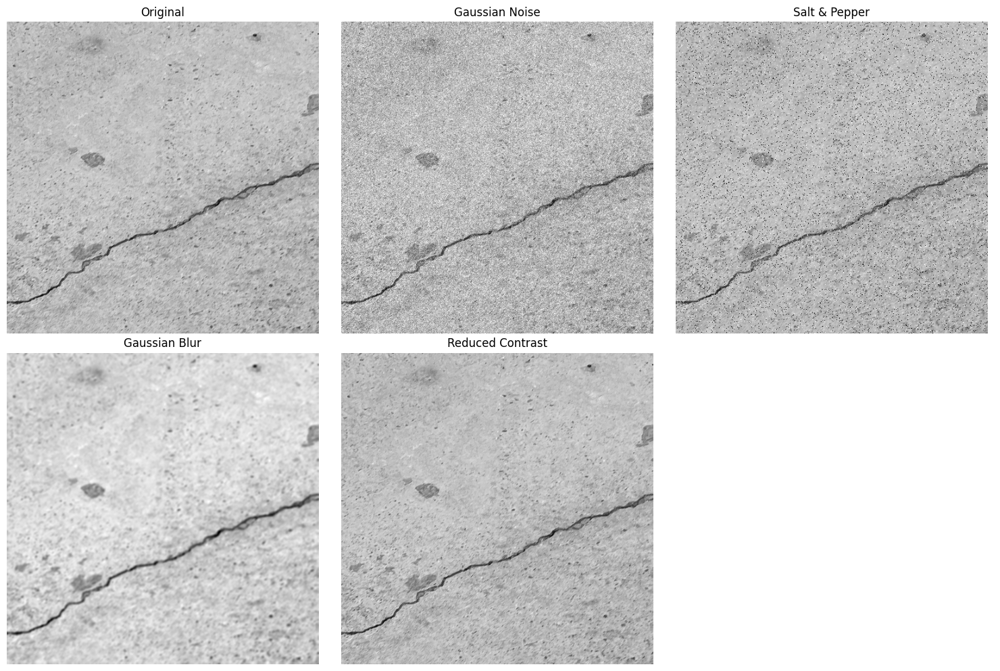

Results saved successfully!
CSV: /content/drive/MyDrive/Image_Processing_Project/Results/Controlled_Degradation/degradation_metrics.csv
Visualization: /content/drive/MyDrive/Image_Processing_Project/Results/Controlled_Degradation/degradation_comparison.png


In [ ]:
#----------------------------------------------------------------------------------
# Create output directory
degradation_dir = os.path.join(
    project_path, "Results", "Controlled_Degradation"
)
os.makedirs(degradation_dir, exist_ok=True)

# Save metrics table
csv_path = os.path.join(
    degradation_dir, "degradation_metrics.csv"
)
degradation_df.to_csv(csv_path, index=False)

# Visual comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

images_to_show = [
    ("Original", original_image),
    ("Gaussian Noise", gaussian_noisy_image),
    ("Salt & Pepper", salt_pepper_image),
    ("Gaussian Blur", gaussian_blurred_image),
    ("Reduced Contrast", reduced_contrast_image)
]

for ax, (title, image_data) in zip(axes.flat, images_to_show):
    ax.imshow(image_data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

# Hide unused subplot
axes.flat[5].axis("off")

plt.tight_layout()

figure_path = os.path.join(
    degradation_dir, "degradation_comparison.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Results saved successfully!")
print("CSV:", csv_path)
print("Visualization:", figure_path)

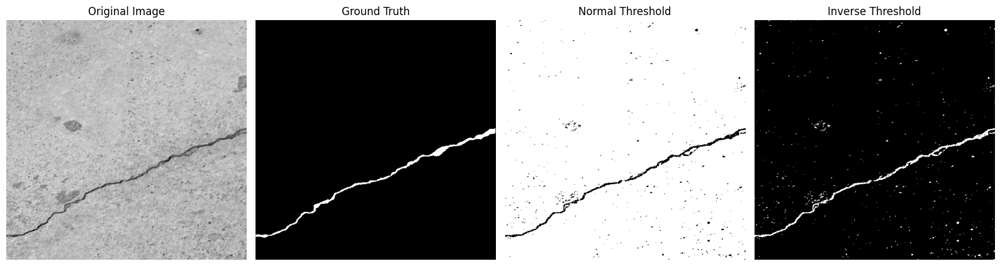

In [7]:
import cv2
import matplotlib.pyplot as plt

# Select one development sample
sample_row = dev_df.iloc[0]

# Load original image
sample_image = cv2.imread(
    sample_row["image_path"],
    cv2.IMREAD_GRAYSCALE
)

# Load original ground truth mask
sample_mask = cv2.imread(
    sample_row["mask_path"],
    cv2.IMREAD_GRAYSCALE
)

# Apply normal and inverse thresholding
_, normal_threshold = cv2.threshold(
    sample_image, 127, 255, cv2.THRESH_BINARY
)

_, inverse_threshold = cv2.threshold(
    sample_image, 127, 255, cv2.THRESH_BINARY_INV
)

# Display comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    ("Original Image", sample_image),
    ("Ground Truth", sample_mask),
    ("Normal Threshold", normal_threshold),
    ("Inverse Threshold", inverse_threshold)
]

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import os
import cv2
import numpy as np

# Output directory
trivial_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Baselines/Trivial_Baseline/Predictions"
os.makedirs(trivial_dir, exist_ok=True)

# Apply fixed inverse threshold = 127
for _, row in dev_df.iterrows():

    image = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)

    _, prediction = cv2.threshold(
        image, 127, 255, cv2.THRESH_BINARY_INV
    )

    filename = os.path.basename(row["image_path"])
    output_path = os.path.join(trivial_dir, filename.replace(".jpg", ".png"))

    cv2.imwrite(output_path, prediction)

print("Trivial Baseline Predictions:", len(os.listdir(trivial_dir)))

Trivial Baseline Predictions: 265


In [9]:
import os

base_path = "/content/drive/MyDrive/Image_Processing_Project/Results"

for root, dirs, files in os.walk(base_path):
    if files and any(f.endswith(".png") for f in files):
        print(root, "->", len([f for f in files if f.endswith(".png")]), "PNG files")

/content/drive/MyDrive/Image_Processing_Project/Results/Image_Analysis -> 2 PNG files
/content/drive/MyDrive/Image_Processing_Project/Results/Resolution_GrayLevel -> 1 PNG files
/content/drive/MyDrive/Image_Processing_Project/Results/Ground_Truth/Development_PNG -> 265 PNG files
/content/drive/MyDrive/Image_Processing_Project/Results/Ground_Truth/Test_PNG -> 114 PNG files
/content/drive/MyDrive/Image_Processing_Project/Results/Controlled_Degradation -> 1 PNG files
/content/drive/MyDrive/Image_Processing_Project/Results/Baselines/Trivial_Baseline/Predictions -> 265 PNG files


In [10]:
import os
import cv2
import numpy as np
import pandas as pd

gt_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Ground_Truth/Development_PNG"

results = []

for _, row in dev_df.iterrows():

    filename = os.path.basename(row["image_path"])
    filename = os.path.splitext(filename)[0] + ".png"

    gt_path = os.path.join(gt_dir, filename)
    pred_path = os.path.join(trivial_dir, filename)

    gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    pred = cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE)

    gt_binary = gt > 127
    pred_binary = pred > 127

    intersection = np.logical_and(gt_binary, pred_binary).sum()
    union = np.logical_or(gt_binary, pred_binary).sum()

    iou = intersection / union if union > 0 else 1.0

    results.append({
        "Image": filename,
        "IoU": iou
    })

trivial_results = pd.DataFrame(results)

print("Evaluated Images:", len(trivial_results))
print("Mean IoU:", round(trivial_results["IoU"].mean(), 4))
print("Minimum IoU:", round(trivial_results["IoU"].min(), 4))
print("Maximum IoU:", round(trivial_results["IoU"].max(), 4))

Evaluated Images: 265
Mean IoU: 0.1571
Minimum IoU: 0.0058
Maximum IoU: 0.8108


In [11]:
import os

baseline_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Baselines/Trivial_Baseline"
os.makedirs(baseline_dir, exist_ok=True)

# Save per-image IoU
trivial_results.to_csv(
    os.path.join(baseline_dir, "trivial_baseline_results.csv"),
    index=False
)

# Save summary
summary = pd.DataFrame([{
    "Baseline": "Trivial Baseline",
    "Method": "Inverse Global Thresholding",
    "Threshold": 127,
    "Evaluated_Images": len(trivial_results),
    "Mean_IoU": trivial_results["IoU"].mean(),
    "Min_IoU": trivial_results["IoU"].min(),
    "Max_IoU": trivial_results["IoU"].max()
}])

summary.to_csv(
    os.path.join(baseline_dir, "trivial_baseline_summary.csv"),
    index=False
)

print("Results Saved Successfully!")
print(summary)

Results Saved Successfully!
           Baseline                       Method  Threshold  Evaluated_Images  \
0  Trivial Baseline  Inverse Global Thresholding        127               265   

   Mean_IoU   Min_IoU   Max_IoU  
0  0.157098  0.005804  0.810789  


In [12]:
import os
import cv2
import numpy as np

# Output directory
simple_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Baselines/Simple_Baseline/Predictions"
os.makedirs(simple_dir, exist_ok=True)

# 3x3 Morphological Kernel
kernel = np.ones((3, 3), np.uint8)

for _, row in dev_df.iterrows():

    # Load grayscale image
    image = cv2.imread(
        row["image_path"],
        cv2.IMREAD_GRAYSCALE
    )

    # Otsu Thresholding (inverse polarity)
    _, otsu_mask = cv2.threshold(
        image,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Morphological Opening
    prediction = cv2.morphologyEx(
        otsu_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # Save prediction
    filename = os.path.splitext(os.path.basename(row["image_path"]))[0] + ".png"
    output_path = os.path.join(simple_dir, filename)

    cv2.imwrite(output_path, prediction)

print("Simple Baseline Predictions:", len(os.listdir(simple_dir)))

Simple Baseline Predictions: 265


In [13]:
results = []

for _, row in dev_df.iterrows():

    filename = os.path.splitext(
        os.path.basename(row["image_path"])
    )[0] + ".png"

    gt_path = os.path.join(gt_dir, filename)
    pred_path = os.path.join(simple_dir, filename)

    gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    pred = cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE)

    gt_binary = gt > 127
    pred_binary = pred > 127

    intersection = np.logical_and(gt_binary, pred_binary).sum()
    union = np.logical_or(gt_binary, pred_binary).sum()

    iou = intersection / union if union > 0 else 1.0

    results.append({
        "Image": filename,
        "IoU": iou
    })

simple_results = pd.DataFrame(results)

print("Evaluated Images:", len(simple_results))
print("Mean IoU:", round(simple_results["IoU"].mean(), 4))
print("Minimum IoU:", round(simple_results["IoU"].min(), 4))
print("Maximum IoU:", round(simple_results["IoU"].max(), 4))

Evaluated Images: 265
Mean IoU: 0.1034
Minimum IoU: 0.0117
Maximum IoU: 0.8555


In [14]:
import os
import pandas as pd

baseline_dir = "/content/drive/MyDrive/Image_Processing_Project/Results/Baselines"
simple_output_dir = os.path.join(baseline_dir, "Simple_Baseline")

os.makedirs(simple_output_dir, exist_ok=True)

# Save per-image results
simple_results.to_csv(
    os.path.join(simple_output_dir, "simple_baseline_results.csv"),
    index=False
)

# Create comparison summary
comparison = pd.DataFrame([
    {
        "Baseline": "Trivial",
        "Method": "Inverse Threshold = 127",
        "Mean_IoU": trivial_results["IoU"].mean()
    },
    {
        "Baseline": "Simple",
        "Method": "Inverse Otsu + 3x3 Opening",
        "Mean_IoU": simple_results["IoU"].mean()
    }
])

comparison.to_csv(
    os.path.join(baseline_dir, "baseline_comparison.csv"),
    index=False
)

print(comparison)
print("\nAll baseline results saved successfully!")

  Baseline                      Method  Mean_IoU
0  Trivial     Inverse Threshold = 127  0.157098
1   Simple  Inverse Otsu + 3x3 Opening  0.103432

All baseline results saved successfully!
